In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
# Constants

T = 1 # Time period
E = 100 # Exercise Price
r = 0.05 # Interest rate
sigma = 0.2 # Volatility
 
# Time step parameter
x_step = 50
t_step = 1000
x_min, x_max = -2, 2
tau_max = T * (sigma**2 / 2)

x = np.linspace(x_min, x_max, x_step)
tau = np.linspace(0, tau_max, t_step)
dx = x[1] - x[0]
dtau = tau[1] - tau[0]

u = np.zeros((x_step, t_step))

In [ ]:
# Payoff Function (european put)
for i in range(x_step):
    u[i,0] = max(1 - np.exp(x[i]), 0)

# FDE
for j in range(t_step - 1):
    for i in range(1, x_step - 1):
        u[i, j+1] = u[i, j] + (dtau / (dx**2)) * (u[i+1, j] - 2*u[i, j] + u[i-1, j])
    
    u[0, j+1] = np.exp(x[-1]) - np.exp(-(2 * r / sigma**2) * tau[j+1])
    u[-1, j+1] = 0

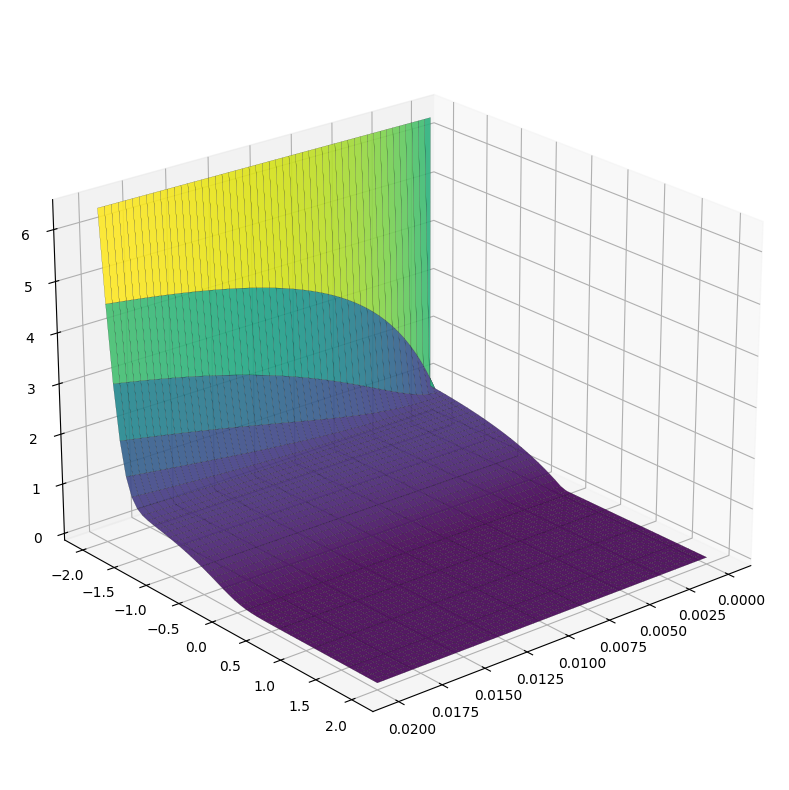

In [64]:
X, T_mesh = np.meshgrid(tau, x)
fig = plt.figure(figsize=(15, 10))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, T_mesh, u, cmap='viridis', edgecolor='k', lw=0.1, alpha=0.9)

ax.view_init(elev=23, azim=-310)
ax.dist = 10 